In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
df = pd.read_csv("train.csv")
df.head()
#CSV file read

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [27]:
df.drop("Unnamed: 0", axis=1, inplace=True)
#unnecessary column deleted
df.head()

,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [28]:
print(df.isnull().sum())
#rows without data were checked

id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction                           0
dtype: int64


In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df = df.dropna(subset=["Arrival Delay in Minutes"])
print("Final Dataset Shape:", df.shape)
print(df.isnull().sum())
#the part without data was deleted
df.head()
df.shape


Final Dataset Shape: (103594, 24)
id                                   0
Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64


(103594, 24)

In [31]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 30, 45, 60, 100],
    labels=["0-18", "19-30", "31-45", "46-60", "60+"]
)

In [32]:
df["Satisfied Flag"] = np.where(df["satisfaction"] == "satisfied", 1, 0)
#if satisfaction value is 1, then satisfied otherwise 0

conditions = [
    df["Arrival Delay in Minutes"] == 0,
    df["Arrival Delay in Minutes"].between(1, 15),
    df["Arrival Delay in Minutes"].between(16, 60),
    df["Arrival Delay in Minutes"] > 60
]
#conditions were created to classify passengers according to their arrival delay time

choices = ["No Delay", "Small Delay", "Medium Delay", "Long Delay"]
df["Delay Category"] = np.select(conditions, choices, default="Unknown")

conditions_distance = [
    df["Flight Distance"] < 500,
    df["Flight Distance"].between(500, 1500),
    df["Flight Distance"] > 1500
]
#flight distance category created

choices_distance = ["Short", "Medium", "Long"]
df["Distance Category"] = np.select(conditions_distance, choices_distance, default="Unknown")

service_columns = [
    "Inflight wifi service", "Ease of Online booking", "Food and drink",
    "Online boarding", "Seat comfort", "Inflight entertainment",
    "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Inflight service", "Cleanliness"
]
#average service score calculated from important service columns

df["Average Service Score"] = df[service_columns].mean(axis=1)

df[["Age", "Age Group", "Arrival Delay in Minutes", "Delay Category", "Flight Distance", "Distance Category", "Average Service Score", "satisfaction"]].head(7)

,Age,Age Group,Arrival Delay in Minutes,Delay Category,Flight Distance,Distance Category,Average Service Score,satisfaction
0,13,0-18,18.0,Medium Delay,460,Short,4.083333,neutral or dissatisfied
1,25,19-30,6.0,Small Delay,235,Short,2.250000,neutral or dissatisfied
2,26,19-30,0.0,No Delay,1142,Medium,4.000000,satisfied
3,25,19-30,9.0,Small Delay,562,Medium,2.666667,neutral or dissatisfied
4,61,60+,0.0,No Delay,214,Short,3.583333,satisfied
5,26,19-30,0.0,No Delay,1180,Medium,2.500000,neutral or dissatisfied
6,47,46-60,23.0,Medium Delay,1276,Medium,2.666667,neutral or dissatisfied


In [33]:
average_age = np.mean(df["Age"])
median_distance = np.median(df["Flight Distance"])
average_arrival_delay = np.mean(df["Arrival Delay in Minutes"])
average_service_score = np.mean(df["Average Service Score"])
satisfaction_rate = np.mean(df["Satisfied Flag"]) * 100

print("Average Age:", round(average_age, 2))
print("Median Flight Distance:", round(median_distance, 2))
print("Average Arrival Delay:", round(average_arrival_delay, 2))
print("Average Service Score:", round(average_service_score, 2))
print("Overall Satisfaction Rate:", round(satisfaction_rate, 2),"%")


Average Age: 39.38
Median Flight Distance: 842.0
Average Arrival Delay: 15.18
Average Service Score: 3.28
Overall Satisfaction Rate: 43.34 %


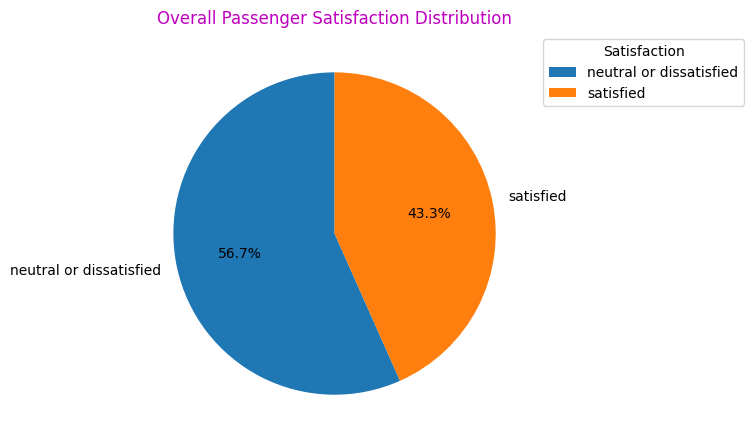

In [34]:
satisfaction_counts = df["satisfaction"].value_counts()

plt.figure()
plt.pie(satisfaction_counts, labels=satisfaction_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Overall Passenger Satisfaction Distribution", color="m")
plt.legend(satisfaction_counts.index, title="Satisfaction", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig("Overall Passenger Satisfaction Distribution.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

In [35]:
age_satisfaction = pd.crosstab(
    df["Age Group"],
    df["satisfaction"],
    normalize="index"
) * 100
print(age_satisfaction)

satisfaction  neutral or dissatisfied  satisfied
Age Group                                       
0-18                        82.730652  17.269348
19-30                       64.569843  35.430157
31-45                       51.275633  48.724367
46-60                       42.560182  57.439818
60+                         79.255252  20.744748


<Figure size 1000x500 with 0 Axes>

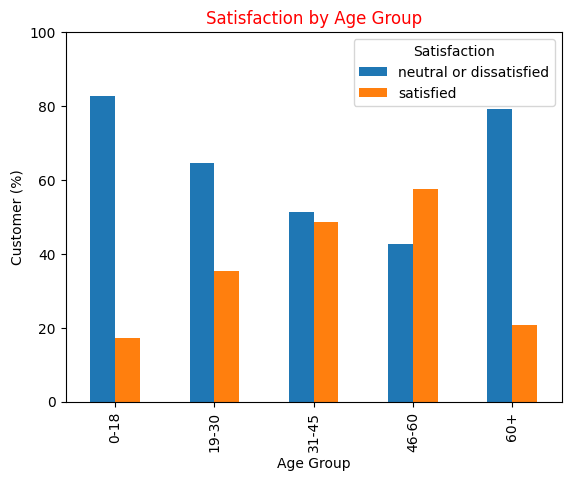

In [36]:
plt.figure(figsize=(10, 5))
age_satisfaction.plot(kind="bar")
plt.title("Satisfaction by Age Group", color="red")
plt.xlabel("Age Group")
plt.ylabel("Customer (%)")
plt.ylim(0, 100)
plt.legend(title="Satisfaction")
plt.savefig("Satisfaction by Age Group.png", dpi=300)
plt.show()

In [37]:
class_satisfaction = df.groupby("Class")["Satisfied Flag"].mean() * 100
print(class_satisfaction)

Class
Business    69.428462
Eco         18.610092
Eco Plus    24.584896
Name: Satisfied Flag, dtype: float64


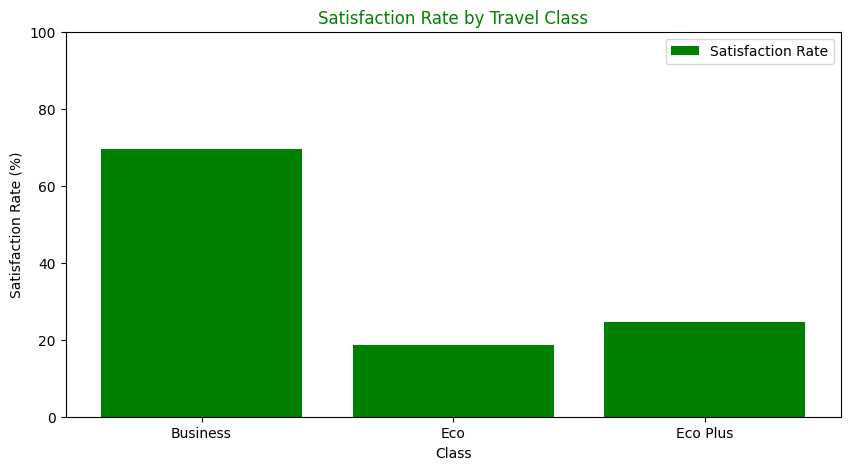

In [38]:
plt.figure(figsize=(10, 5))
plt.bar(class_satisfaction.index, class_satisfaction.values, label="Satisfaction Rate",color="green")
plt.title("Satisfaction Rate by Travel Class", color="green")
plt.xlabel("Class")
plt.ylabel("Satisfaction Rate (%)")
plt.ylim(0, 100)
plt.legend()
plt.savefig("Satisfaction Rate by Travel Class.png", dpi=300)
plt.show()

In [39]:
delay_order = ["No Delay", "Small Delay", "Medium Delay", "Long Delay"]
df["Delay Category"] = pd.Categorical(df["Delay Category"], categories=delay_order, ordered=True)
delay_satisfaction = df.groupby("Delay Category")["Satisfied Flag"].mean() * 100

print(delay_satisfaction)

Delay Category
No Delay        47.279011
Small Delay     41.302752
Medium Delay    35.436596
Long Delay      35.717210
Name: Satisfied Flag, dtype: float64


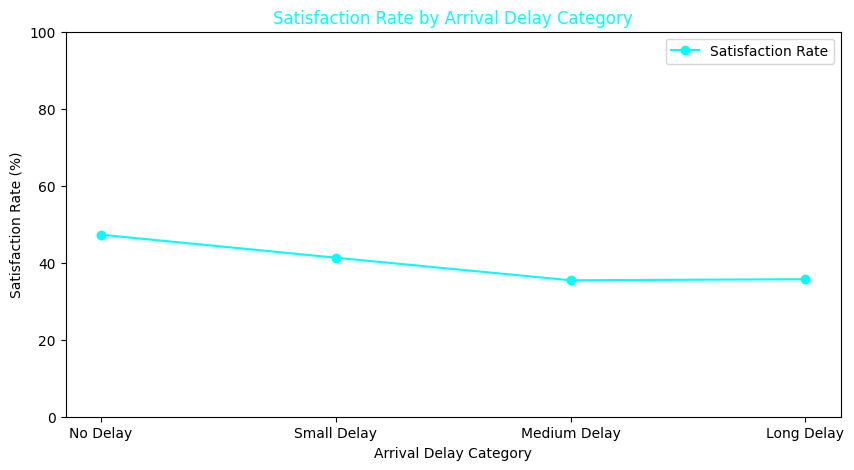

In [40]:
plt.figure(figsize=(10, 5))
plt.plot(delay_satisfaction.index, delay_satisfaction.values, marker="o", label="Satisfaction Rate", color="cyan")
plt.title("Satisfaction Rate by Arrival Delay Category", color="cyan")
plt.xlabel("Arrival Delay Category")
plt.ylabel("Satisfaction Rate (%)")
plt.ylim(0, 100)
plt.legend()
plt.savefig("Satisfaction Rate by Arrival Delay Category.png", dpi=300)
plt.show()

In [41]:
service_satisfaction = df.groupby("satisfaction")[service_columns].mean().transpose()
#the average score of each service variable was calculated separately
#transpose() was used to make service variables appear as rows
service_satisfaction["Difference"] = service_satisfaction["satisfied"] - service_satisfaction["neutral or dissatisfied"]
service_satisfaction = service_satisfaction.sort_values("Difference")
print(service_satisfaction)


satisfaction            neutral or dissatisfied  satisfied  Difference
Ease of Online booking                 2.547149   3.031316    0.484167
Food and drink                         2.958362   3.520814    0.562452
Inflight service                       3.389015   3.969887    0.580872
Baggage handling                       3.375709   3.966345    0.590636
Checkin service                        3.043239   3.645656    0.602417
Inflight wifi service                  2.399748   3.161191    0.761443
Cleanliness                            2.936317   3.744081    0.807764
Leg room service                       2.991107   3.822438    0.831331
On-board service                       3.019303   3.857585    0.838283
Seat comfort                           3.037072   3.966234    0.929162
Inflight entertainment                 2.894100   3.965276    1.071176
Online boarding                        2.656337   4.027285    1.370948


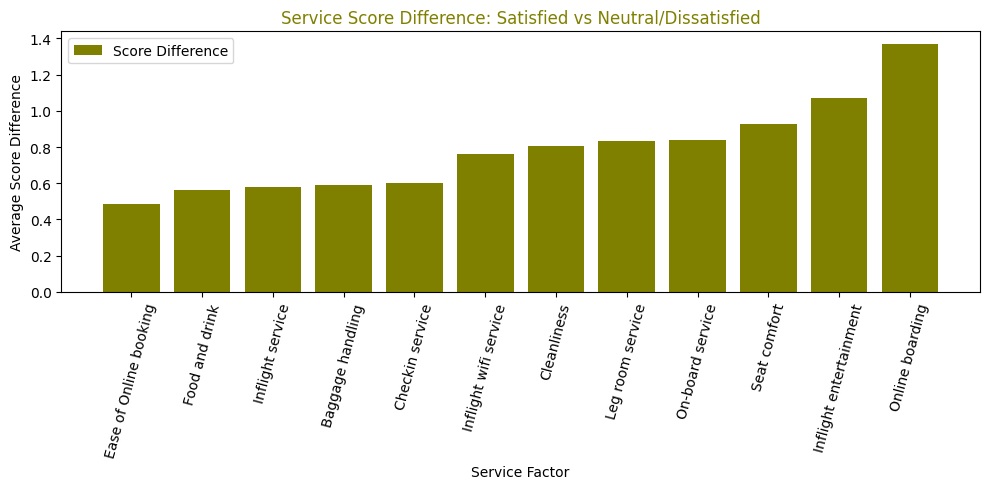

In [42]:
plt.figure(figsize=(10, 5))
plt.bar(service_satisfaction.index, service_satisfaction["Difference"], label="Score Difference", color="olive")
plt.title("Service Score Difference: Satisfied vs Neutral/Dissatisfied", color="olive")
plt.xlabel("Service Factor")
plt.ylabel("Average Score Difference")
plt.xticks(rotation=75)
plt.legend()
plt.tight_layout()
plt.savefig("Service Score Difference.png", dpi=300)
plt.show()

In [43]:
distance_order = ["Short", "Medium", "Long"]
distance_satisfaction = df.groupby("Distance Category")["Satisfied Flag"].mean().reindex(distance_order) * 100
print(distance_satisfaction)

Distance Category
Short     33.318783
Medium    33.691997
Long      65.929302
Name: Satisfied Flag, dtype: float64


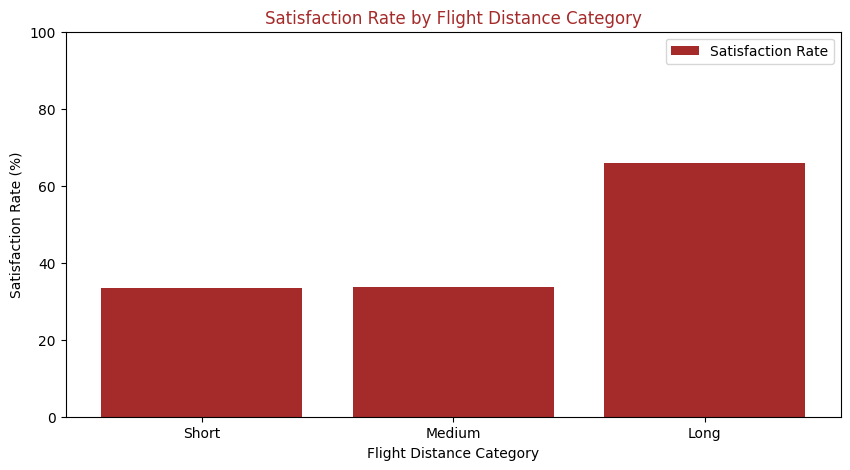

In [44]:
plt.figure(figsize=(10, 5))
plt.bar(distance_satisfaction.index, distance_satisfaction.values, label="Satisfaction Rate", color="brown")
plt.title("Satisfaction Rate by Flight Distance Category", color="brown")
plt.xlabel("Flight Distance Category")
plt.ylabel("Satisfaction Rate (%)")
plt.ylim(0, 100)
plt.legend()
plt.savefig("Satisfaction Rate by Flight Distance Category.png", dpi=300)
plt.show()

In [45]:
distance_class_table = pd.crosstab(df["Distance Category"], df["Class"])
print(distance_class_table)

Class              Business    Eco  Eco Plus
Distance Category                           
Long                  26231   4341       801
Medium                13247  23374      3528
Short                 10055  18878      3139


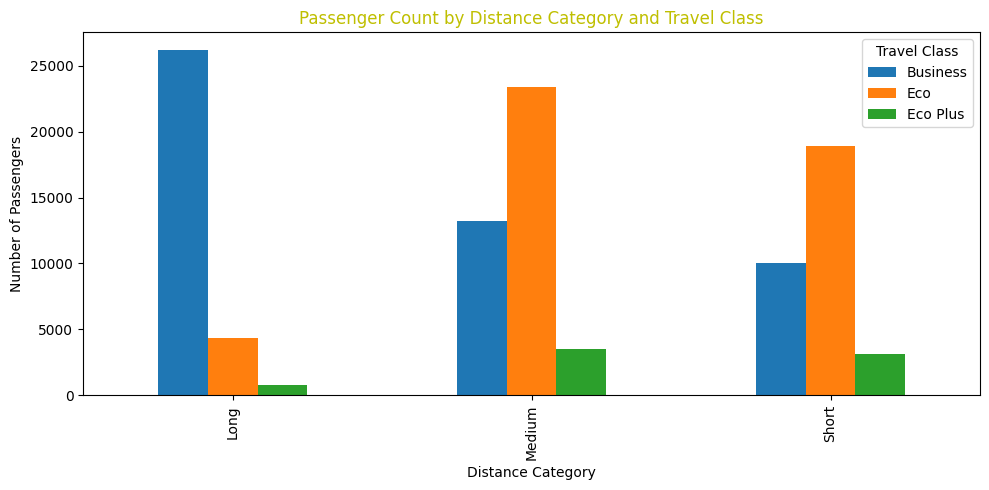

In [46]:
distance_class_table.plot(kind="bar", figsize=(10, 5))

plt.title("Passenger Count by Distance Category and Travel Class", color="y")
plt.xlabel("Distance Category")
plt.ylabel("Number of Passengers")
plt.legend(title="Travel Class")
plt.tight_layout()
plt.savefig("Passenger Count by Distance Category and Travel Class.png", dpi=300)
plt.show()

In [47]:
selected_numeric_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
    "Average Service Score",
    "Satisfied Flag"
]

correlation_matrix = df[selected_numeric_cols].corr()
print(correlation_matrix)

                                 Age  Flight Distance  \
Age                         1.000000         0.099838   
Flight Distance             0.099838         1.000000   
Departure Delay in Minutes -0.010150         0.001906   
Arrival Delay in Minutes   -0.012147        -0.002426   
Average Service Score       0.094885         0.178333   
Satisfied Flag              0.137040         0.298915   

                            Departure Delay in Minutes  \
Age                                          -0.010150   
Flight Distance                               0.001906   
Departure Delay in Minutes                    1.000000   
Arrival Delay in Minutes                      0.965481   
Average Service Score                        -0.035553   
Satisfied Flag                               -0.050515   

                            Arrival Delay in Minutes  Average Service Score  \
Age                                        -0.012147               0.094885   
Flight Distance                    

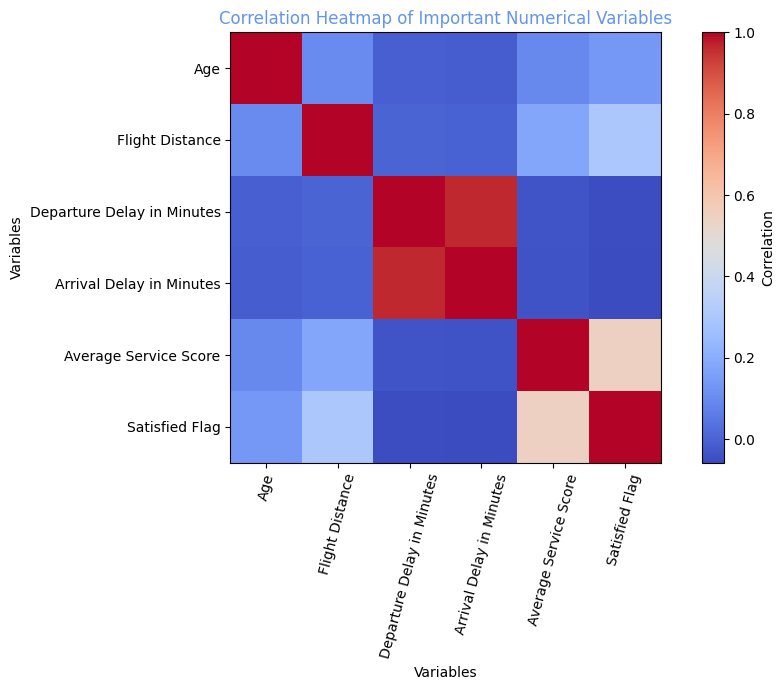

In [48]:
plt.figure(figsize=(10, 7))
plt.imshow(correlation_matrix, cmap="coolwarm")
plt.colorbar(label="Correlation")
plt.xticks(range(len(selected_numeric_cols)), selected_numeric_cols, rotation=75)
plt.yticks(range(len(selected_numeric_cols)), selected_numeric_cols)
plt.title("Correlation Heatmap of Important Numerical Variables", color="cornflowerblue")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.tight_layout()
plt.savefig("Correlation Heatmap of Important Numerical Variables.png", dpi=300)
plt.show()